# Local Photometry: Apertures, PSF and Upper Limits

This example shows the local photometry at the position of SN 2009ig, in its host NGC 1015, with images of very different resolution (PanSTARRS, 2MASS and WISE): apertures in physical and angular units, the PSF size of each image, the upper limits for non-detections and the quality flags.

In [1]:
import hostphot
print('HostPhot version:', hostphot.__version__)

HostPhot version: 4.0.0


In [2]:
import pandas as pd
from hostphot.utils import plot_image
from hostphot.cutouts import download_images
from hostphot.processing import coadd_images, create_mask
from hostphot.photometry import local_photometry as lp
from hostphot.surveys_utils import get_survey_filters

name = 'SN2009ig'
ra, dec = 39.548375, -1.312556  # SN
host_ra, host_dec = 39.5482, -1.3187  # NGC 1015
z = 0.0088

surveys = ['PanSTARRS', '2MASS', 'WISE']
for survey in surveys:
    download_images(name, host_ra, host_dec, survey=survey, size=7, overwrite=False)

## Masking

The local photometry can also use masked images (`use_mask=True`, the default), so that foreground stars or neighbouring galaxies do not contaminate the apertures. As in the global photometry example, the mask is measured on a PanSTARRS coadd, with a model of the host galaxy (only the stars and the sources much brighter than the host are masked), and applied to all the images:

In [3]:
coadd_images(name, filters='riz', survey='PanSTARRS')
create_mask(name, host_ra, host_dec, filt='riz', survey='PanSTARRS', method='host_model',
            crossmatch=True, save_mask_params=True)

for survey in surveys:
    for filt in get_survey_filters(survey):
        create_mask(name, host_ra, host_dec, filt=filt, survey=survey,
                    ref_filt='riz', ref_survey='PanSTARRS', save_input=False)

## Apertures in kpc and arcsec

By default, the aperture radii are in kpc (`ap_units="kpc"`), converted into an angular size with the redshift and a flat ΛCDM cosmology (`H0=70`, `Om0=0.3`; it can be changed with `lp.choose_cosmology()`):

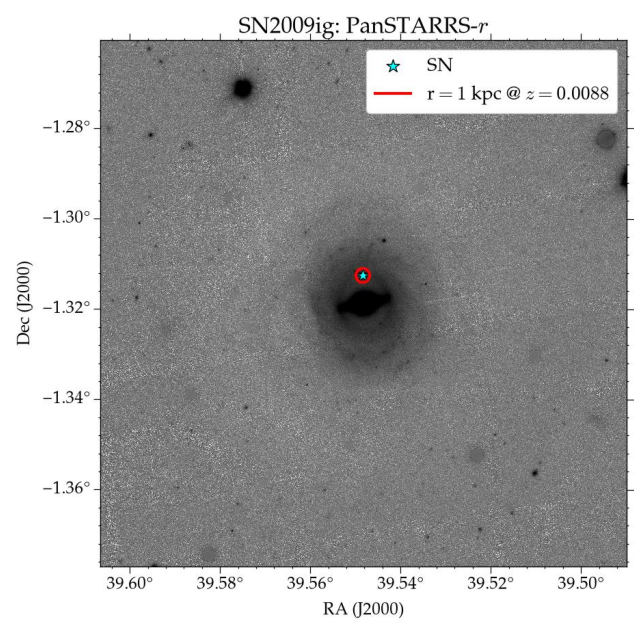

In [4]:
ps = lp.multi_band_phot(name, ra, dec, z, survey='PanSTARRS', ap_radii=[1, 2, 4], save_plots=True)
plot_image(f'images/{name}/PanSTARRS/local_PanSTARRS_r_1kpc.jpg')

The columns are named after the filter and the aperture radius (e.g. `r_1`, `r_1_err` for 1 kpc), with the same outputs as the global photometry: AB magnitudes, flux densities in µJy, 3-sigma upper limits and the quality flags. The PSF FWHM of each image (`{filt}_psf_fwhm`, in arcsec) is also given:

In [5]:
def summary(df, filters, radii):
    rows = []
    for filt in filters:
        for radius in radii:
            col = f'{filt}_{radius}'
            if col not in df.columns:
                continue
            flags = [flag for flag in ['bkg', 'coverage', 'psf', 'err'] if df[f'{col}_{flag}_flag'].iloc[0]]
            rows.append([filt, radius, df[col].iloc[0], df[f'{col}_err'].iloc[0], df[f'{col}_AB'].iloc[0],
                         df[f'{col}_flux_uJy'].iloc[0], df[f'{col}_AB_ulim'].iloc[0],
                         df[f'{filt}_psf_fwhm'].iloc[0], ', '.join(flags)])
    return pd.DataFrame(rows, columns=['filter', 'radius', 'mag', 'mag_err', 'AB', 'flux_uJy', 'AB_ulim',
                                       'psf_fwhm', 'flags'])

summary(ps, 'grizy', [1, 2, 4]).round(3)

,filter,radius,mag,mag_err,AB,flux_uJy,AB_ulim,psf_fwhm,flags
0,g,1,18.043,0.028,18.043,220.284,20.835,1.31,err
1,g,2,16.536,0.026,16.536,882.347,19.378,1.31,err
2,g,4,14.216,0.022,14.216,7475.398,17.240,1.31,
3,r,1,17.339,0.017,17.339,421.091,20.653,1.19,err
4,r,2,15.828,0.015,15.828,1693.547,19.251,1.19,err
5,r,4,13.475,0.016,13.475,14786.117,16.866,1.19,
6,i,1,17.015,0.017,17.015,567.440,20.329,1.11,err
7,i,2,15.511,0.018,15.511,2268.512,18.778,1.11,err
8,i,4,13.127,0.022,13.127,20385.991,16.146,1.11,
9,z,1,16.894,0.023,16.894,634.538,19.891,1.07,err


At $z=0.0088$, 1 kpc corresponds to ~5.5 arcsec. The radii can also be given in arcsec with `ap_units="arcsec"`, e.g. to use the same angular aperture for objects at different redshifts:

In [6]:
ps_arcsec = lp.multi_band_phot(name, ra, dec, z, survey='PanSTARRS', ap_radii=[3, 6], ap_units='arcsec',
                               save_plots=False, save_results=False)
summary(ps_arcsec, 'gri', [3, 6]).round(3)

,filter,radius,mag,mag_err,AB,flux_uJy,AB_ulim,psf_fwhm,flags
0,g,3,19.326,0.056,19.326,67.539,21.343,1.31,
1,g,6,17.869,0.028,17.869,258.423,20.648,1.31,err
2,r,3,18.641,0.018,18.641,126.980,21.926,1.19,err
3,r,6,17.166,0.018,17.166,493.854,20.424,1.19,err
4,i,3,18.318,0.020,18.318,170.993,21.436,1.11,err
5,i,6,16.847,0.017,16.847,662.592,20.169,1.11,err


## PSF and resolution

The flux within a small aperture depends on the resolution of the image: for apertures smaller than the PSF, part of the flux of the region is spread outside the aperture, while the light of the surroundings is spread into it. HostPhot gives a warning and sets the `psf` flag when the aperture radius is smaller than the PSF FWHM, which happens for WISE (6-12 arcsec) with a 1-kpc aperture:

In [7]:
wise = lp.multi_band_phot(name, ra, dec, z, survey='WISE', ap_radii=[1, 4], save_plots=True)

In [8]:
summary(wise, ['W1', 'W2', 'W3', 'W4'], [1, 4]).round(3)

,filter,radius,mag,mag_err,AB,flux_uJy,AB_ulim,psf_fwhm,flags
0,W1,1,14.321,0.024,17.020,564.825,19.973,6.1,psf
1,W1,4,10.608,0.007,13.307,17270.333,17.546,6.1,err
2,W2,1,14.309,0.037,17.648,316.930,20.124,6.4,psf
3,W2,4,10.595,0.010,13.934,9692.018,17.878,6.4,
4,W3,1,12.547,0.136,17.721,296.130,18.785,6.5,psf
5,W3,4,9.293,0.047,14.467,5933.506,16.683,6.5,
6,W4,1,NaN,NaN,NaN,-6.758,17.806,12.0,"bkg, psf"
7,W4,4,9.444,0.813,16.064,1362.144,15.186,12.0,bkg


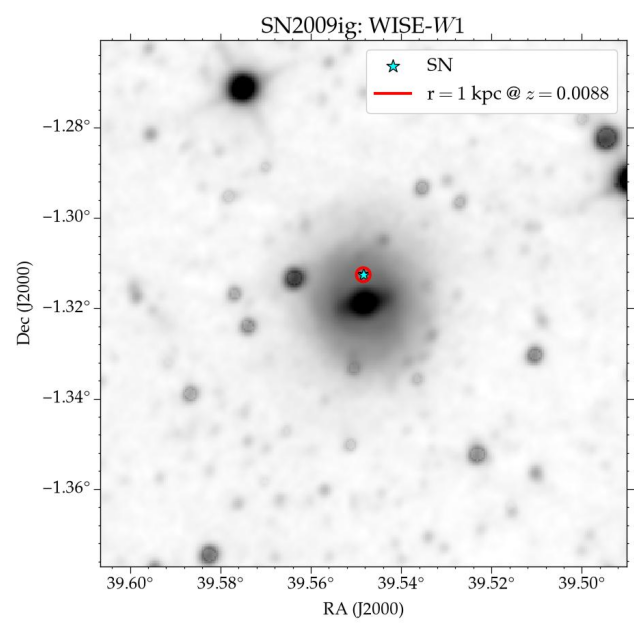

In [9]:
plot_image(f'images/{name}/WISE/local_WISE_W1_1kpc.jpg')

In W4, the SN region is not detected in the 1-kpc aperture: the flux is negative, so the magnitude is NaN, while the flux and its uncertainty are kept and the 3-sigma upper limit (`AB_ulim`) can be used instead. The `bkg` flag also marks the W4 apertures where the background follows the outskirts of the galaxy (the galaxy fills most of the low-resolution image), so their fluxes are not reliable.

## SED

The SED of the local photometry is plotted for a given aperture radius (upper limits for the non-detections):

In [10]:
_ = lp.multi_band_phot(name, ra, dec, z, survey='2MASS', ap_radii=[1, 4], save_plots=False)

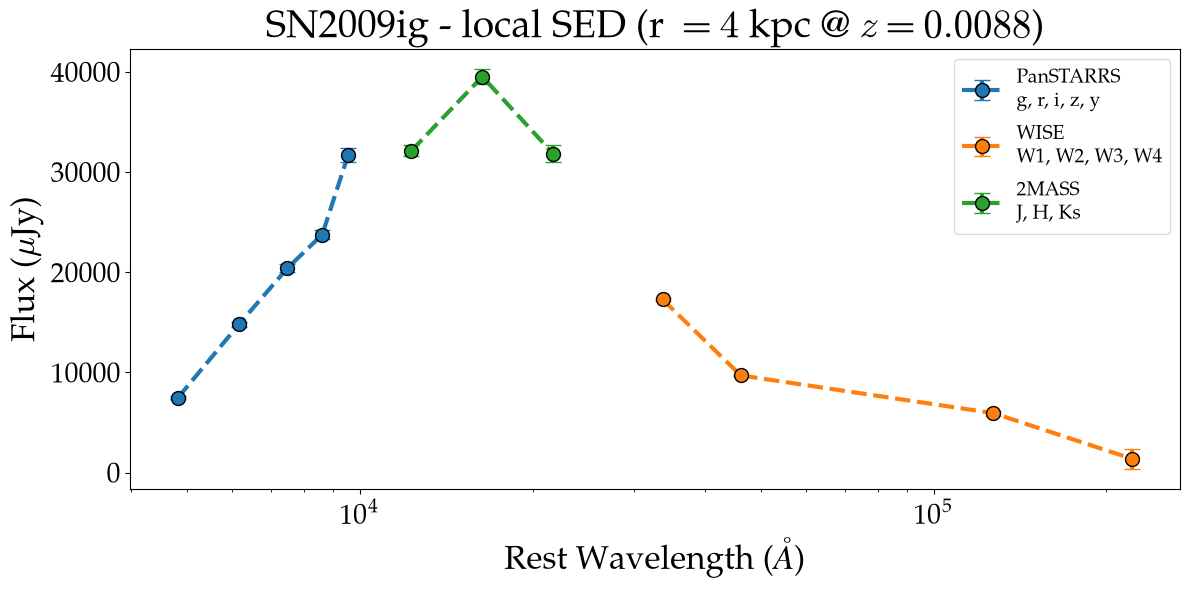

In [11]:
from hostphot.photometry.sed_plotting import plot_sed

plot_sed(name, phot_type='local', z=z, radius=4, plot_flux=True)